# Homogeneous MCWF squeezing

Compare homogeneous MCWF squeezing dynamics for several atom numbers. The drive, detuning, and timestep follow the shared $N\Gamma$-scaled conventions, while the binomial sector window includes two standard deviations around $N_J=N/2$.

## Imports

In [1]:
from pathlib import Path
import sys

import numpy as np

repo_root = Path.cwd().resolve()
if repo_root.name == "notebooks":
    repo_root = repo_root.parent
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from common.plotting import (
    plot_bloch_angles,
    plot_spin_components,
    plot_squeezing,
)
from common.utils.parameters import (
    mcwf_dt_from_scales,
    omega_c,
    scaled_N_Gamma,
)
from common.utils.phases import default_three_phase_protocol
from parser.mcwf import MCWFSolverParameters
from parser.moments import MomentSeries, SimulationMetadata
from post_analysis import compute_squeezing
from solvers.mcwf.ensamble_sim import run_trajectory_ensemble
from solvers.mcwf.j_moments import compute_mcwf_j_moments
from solvers.mcwf.s_moments import compute_mcwf_s_moments
from solvers.mcwf.squeezing_moments import (
    compute_mcwf_squeezing_moments,
)

%reload_ext autoreload
%autoreload 2

/Users/ashar/.pyenv/versions/cavity-OAT_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Parameters

In [ ]:
Gamma = 1.0
N_values = (10, 50, 100)
sector_standard_deviations = 1.0
ntraj = 100
num_snapshots = 100
n_processes = -1
seed = 1234

Omega_factor = 0.1
delta_factor = 0.02
durations = (10.0, 10.0, 10.0)

# For N_J ~ Binomial(N, 1/2), sigma_NJ = sqrt(N) / 2.
dN_by_N = {
    N: int(np.ceil(sector_standard_deviations * np.sqrt(N) / 2.0))
    for N in N_values
}


# FIXME 
N_values = [100]
dN_by_N = {100:5}

print(dN_by_N)

{100: 10}


## MCWF simulations and squeezing analysis

In [3]:
moments_by_N = {}

for N in N_values:
    Omega0 = scaled_N_Gamma(Omega_factor, N, Gamma)
    delta0 = scaled_N_Gamma(delta_factor, N, Gamma)
    dt = mcwf_dt_from_scales(Omega0, delta0, N, Gamma)
    dN = dN_by_N[N]

    phase_protocol = default_three_phase_protocol(
        durations=durations,
        delta0=delta0,
        Omega0=Omega0,
    )
    metadata = SimulationMetadata(
        Ni=(N,),
        omega_i=(),
        Gamma=Gamma,
        phase_protocol=phase_protocol,
    )
    moments = MomentSeries(
        num_snapshots=num_snapshots,
        metadata=metadata,
    )
    parameters = MCWFSolverParameters(
        Ni=metadata.Ni,
        omega_i=metadata.omega_groups,
        Gamma=metadata.Gamma,
        phase_protocol=metadata.phase_protocol,
        dN=dN,
        sector_distribution="binomial",
        dt=dt,
        shifted_jump_operator=True,
    )

    print(
        f"N={N}: dN={dN}, Omega0={Omega0:g}, delta0={delta0:g}, "
        f"min-sector Omega0/Omega_c="
        f"{Omega0 / omega_c(N // 2 - dN, Gamma):.3f}, "
        f"dt={dt:g}"
    )
    ensemble = run_trajectory_ensemble(
        parameters,
        t_eval=moments.t,
        seed=seed,
        ntraj=ntraj,
        n_processes=n_processes,
        verbose=True,
    )

    moments.J = compute_mcwf_j_moments(
        ensemble,
        n_processes=n_processes,
    )
    moments.S = compute_mcwf_s_moments(
        ensemble,
        moments.J,
        n_processes=n_processes,
    )
    moments.squeezing_moments = compute_mcwf_squeezing_moments(
        ensemble,
        moments.J,
        moments.S,
        n_processes=n_processes,
    )
    moments.squeezing = compute_squeezing(moments.squeezing_moments)
    moments_by_N[N] = moments

    # The derived moments no longer depend on retaining the raw ensemble.
    del ensemble

N=100: dN=10, Omega0=10, delta0=2, min-sector Omega0/Omega_c=0.500, dt=0.001
Precompute: 0.13 seconds.
Pool startup: 10 processes in 6.19 seconds.


simulate trajectories: 100%|██████████| 100/100 [00:43<00:00,  2.29it/s]

Simulation step summary (avg per trajectory): total steps=30166.42, steps without precompute=169.41



compute_mcwf_squeezing_fluctuation_moments: 100%|██████████| 100/100 [00:04<00:00, 22.34it/s]


## Plots

(<Figure size 1000x700 with 4 Axes>,
 array([<Axes: title={'center': 'Generalized squeezing'}, ylabel='$\\xi^2$ [dB]'>,
        <Axes: title={'center': 'Covariance eigenvalues'}, ylabel='$\\lambda_i(C)$'>,
        <Axes: title={'center': 'Mean population'}, ylabel='$\\langle N_c\\rangle$'>,
        <Axes: title={'center': 'Active excited fraction'}, ylabel='$\\langle N_e\\rangle/\\langle N_J\\rangle$'>],
       dtype=object))

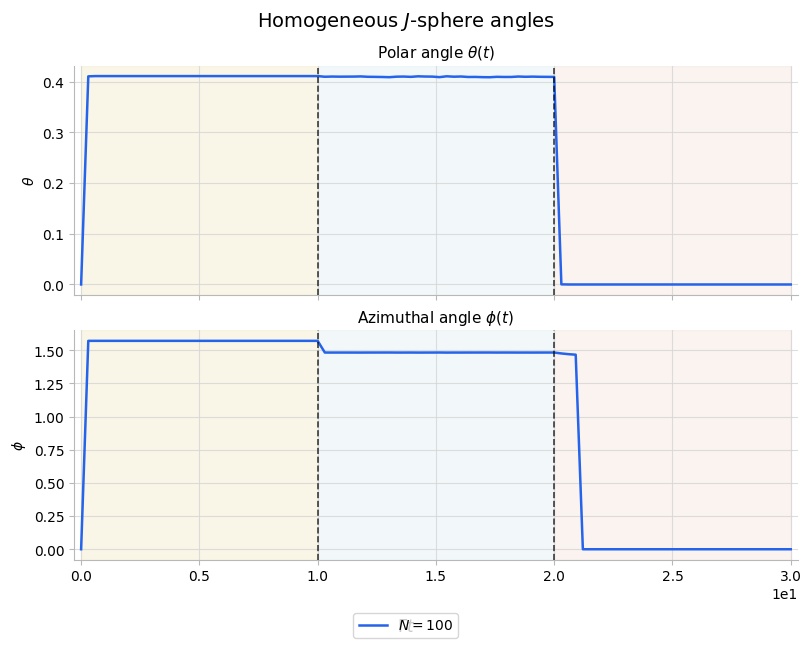

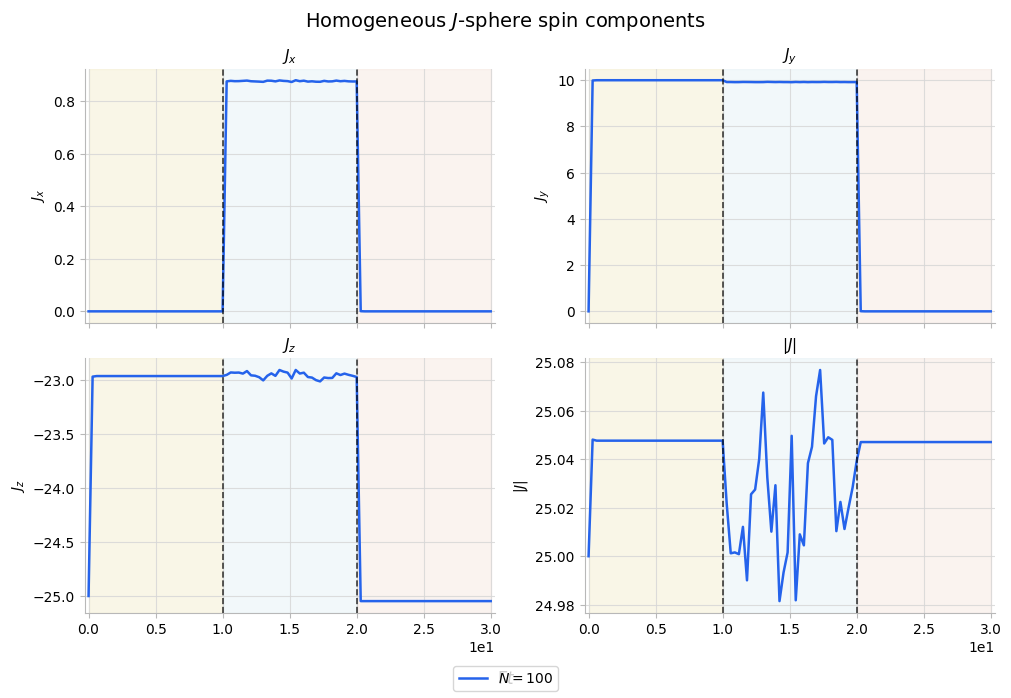

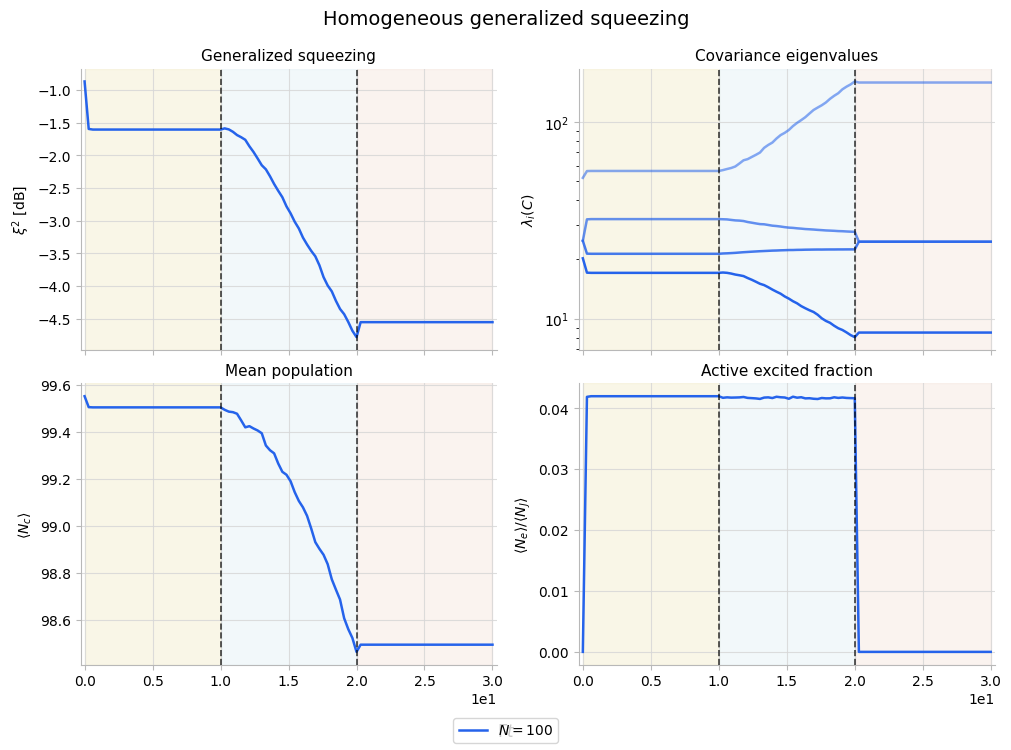

In [4]:
labels = [rf"$N={N}$" for N in N_values]
j_series = [moments_by_N[N].J for N in N_values]
squeezing_series = [moments_by_N[N].squeezing[0] for N in N_values]
t = j_series[0].t
phase_protocol = moments_by_N[N_values[0]].metadata.phase_protocol

if any(not np.allclose(series.t, t) for series in j_series[1:]):
    raise ValueError("All runs must share the same saved-time grid.")

plot_bloch_angles(
    t,
    [series.theta[0] for series in j_series],
    [series.phi[0] for series in j_series],
    labels=labels,
    phase_protocol=phase_protocol,
    colour_family_index=None,
    shade_index=3,
    title=r"Homogeneous $J$-sphere angles",
)

plot_spin_components(
    t,
    [series.x[0] for series in j_series],
    [series.y[0] for series in j_series],
    [series.z[0] for series in j_series],
    [series.length[0] for series in j_series],
    labels=labels,
    phase_protocol=phase_protocol,
    colour_family_index=None,
    shade_index=3,
    title=r"Homogeneous $J$-sphere spin components",
)

plot_squeezing(
    squeezing_series[0].t,
    [series.xi2 for series in squeezing_series],
    [series.lambda_min for series in squeezing_series],
    [series.N_c for series in squeezing_series],
    [series.excited_fraction_active for series in squeezing_series],
    covariance_eigvals=[
        series.covariance_eigvals for series in squeezing_series
    ],
    plot_all_eigenvalues=True,
    labels=labels,
    phase_protocol=phase_protocol,
    colour_family_index=None,
    shade_index=3,
    title="Homogeneous generalized squeezing",
)